# Customer Review Sentiment Analysis using BERT

Capstone project. Dataset: IMDb Large Movie Review Dataset (`stanfordnlp/imdb` on Hugging Face), label mapping 0 = negative, 1 = positive.
Models: TF-IDF + Logistic Regression (baseline) and fine-tuned DistilBERT.

## 1. Setup

In [1]:
import torch
assert torch.cuda.is_available(), "no gpu found, set the runtime type to T4 GPU"
print(torch.cuda.get_device_name(0))

Tesla T4


# Installing datasets

In [2]:
!pip install -q datasets evaluate accelerate

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 1.8 MB/s eta 0:00:00


In [3]:
import os, re, json, time, random, warnings, shutil, gc
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm
warnings.filterwarnings("ignore")

SEED = 42
LABELS = {0: "Negative", 1: "Positive"}
MODEL_NAME = "distilbert-base-uncased"
FINAL_DIR = "models/distilbert_sentiment"

os.makedirs("models", exist_ok=True)
os.makedirs("reports", exist_ok=True)
device = torch.device("cuda")
use_amp = True

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

def clean_text(text):
    # imdb reviews have <br /> tags in them
    text = re.sub(r"<br\s*/?>", " ", text)
    return re.sub(r"\s+", " ", text).strip()

def log_experiment(model, params, val_acc, val_f1, train_time_s, path="reports/experiments.csv"):
    row = pd.DataFrame([{"model": model, "params": params, "val_accuracy": round(val_acc, 4),
                         "val_f1": round(val_f1, 4), "train_time_s": round(train_time_s, 1)}])
    row.to_csv(path, mode="a", header=not os.path.exists(path), index=False)

from transformers import AutoModelForSequenceClassification
def load_clf(path_or_name, **kw):
    # fall back to the distilbert class directly if the auto loader fails
    try:
        return AutoModelForSequenceClassification.from_pretrained(path_or_name, **kw)
    except Exception:
        from transformers.models.distilbert.modeling_distilbert import DistilBertForSequenceClassification
        return DistilBertForSequenceClassification.from_pretrained(path_or_name, **kw)

set_seed()

## 2. Data

In [4]:
from datasets import load_dataset, Dataset, DatasetDict

raw = load_dataset("stanfordnlp/imdb")
print(raw)
print("Label mapping:", LABELS)
ex = raw["train"][0]
print(ex["label"], ex["text"][:300])

README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

...

plain_text/unsupervised-00000-of-00001.p(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    unsupervised: Dataset({
        features: ['text', 'label'],
        num_rows: 50000
    })
})
Label mapping: {0: 'Negative', 1: 'Positive'}
0 I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ever tried to enter this country, therefore being a fan of films considered "controversial" I really h


In [5]:
sample = next(t for t in raw["train"]["text"][:200] if "<br" in t)
print("BEFORE:", sample[:250])
print("AFTER :", clean_text(sample)[:250])

BEFORE: I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ever tried to enter this country, therefore being a 
AFTER : I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ever tried to enter this country, therefore being a 


In [6]:
# not using the unsupervised split since it has no labels
raw = DatasetDict({"train": raw["train"], "test": raw["test"]})
raw = raw.map(lambda x: {"text": clean_text(x["text"])})

# some reviews are repeated inside train and some test reviews are also in train
# so dropping those, otherwise the test score is slightly optimistic
train_df = raw["train"].to_pandas()
n_train_dups = int(train_df["text"].duplicated().sum())
train_df = train_df.drop_duplicates(subset="text")

test_df = raw["test"].to_pandas()
n_test_overlap = int(test_df["text"].isin(set(train_df["text"])).sum())
test_df = test_df[~test_df["text"].isin(set(train_df["text"]))].drop_duplicates(subset="text")
print(f"removed {n_train_dups} duplicate reviews from train and {n_test_overlap} test reviews that were also in train")

train_ds = Dataset.from_pandas(train_df, preserve_index=False).class_encode_column("label")
test_ds = Dataset.from_pandas(test_df, preserve_index=False)

# 90/10 stratified train/validation split
split = train_ds.train_test_split(test_size=0.1, seed=SEED, stratify_by_column="label")
train_full, val_full = split["train"], split["test"]
print(f"Train: {len(train_full)} | Validation: {len(val_full)} | Test: {len(test_ds)}")

Map:   0%|          | 0/25000 [00:00<?, ? examples/s]

Map:   0%|          | 0/25000 [00:00<?, ? examples/s]

removed 98 duplicate reviews from train and 123 test reviews that were also in train


Stringifying the column:   0%|          | 0/24902 [00:00<?, ? examples/s]

Casting to class labels:   0%|          | 0/24902 [00:00<?, ? examples/s]

Train: 22411 | Validation: 2491 | Test: 24676


In [7]:
for name, ds in [("train", train_full), ("validation", val_full), ("test", test_ds)]:
    d = ds.to_pandas()
    print(f"{name:10s} size={len(d):6d} | missing text={d['text'].isnull().sum()} | "
          f"negative={int((d['label']==0).sum())} positive={int((d['label']==1).sum())}")

all_train_texts = set(train_full["text"]) | set(val_full["text"])
print("reviews in both train/val and test:", len(all_train_texts & set(test_ds["text"])))

train      size= 22411 | missing text=0 | negative=11188 positive=11223
validation size=  2491 | missing text=0 | negative=1243 positive=1248
test       size= 24676 | missing text=0 | negative=12265 positive=12411
reviews in both train/val and test: 0


## 3. EDA

In [8]:
from transformers import AutoTokenizer

df = train_full.to_pandas()
df["sentiment"] = df["label"].map(LABELS)
df["words"] = df["text"].str.split().str.len()

print("Missing values:", df.isnull().sum().to_dict())
print("Duplicate reviews in train:", int(df["text"].duplicated().sum()))
print("Empty reviews:", int((df["words"] == 0).sum()))
print(df["sentiment"].value_counts())
print(df.groupby("sentiment")["words"].describe().round(1))

# how many reviews fit in the max token length
eda_tok = AutoTokenizer.from_pretrained(MODEL_NAME)
sample_df = df.sample(2000, random_state=SEED)
lens = np.array([len(x) for x in eda_tok(sample_df["text"].tolist(), truncation=False)["input_ids"]])
for n in (128, 256, 384, 512):
    print(f"fit in {n} tokens: {(lens <= n).mean():.1%}")

for lab in (0, 1):
    for t in df[df["label"] == lab]["text"].head(2):
        print(f"[{LABELS[lab]}] {t[:300]}...\n")

Missing values: {'text': 0, 'label': 0, 'sentiment': 0, 'words': 0}
Duplicate reviews in train: 0
Empty reviews: 0
sentiment
Positive    11223
Negative    11188
Name: count, dtype: int64
             count   mean    std   min    25%    50%    75%     max
sentiment                                                          
Negative   11188.0  228.9  164.9  10.0  127.0  174.0  276.0  1491.0
Positive   11223.0  235.5  180.5  12.0  125.0  173.0  288.0  2459.0


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (558 > 512). Running this sequence through the model will result in indexing errors


fit in 128 tokens: 11.9%
fit in 256 tokens: 58.8%
fit in 384 tokens: 77.7%
fit in 512 tokens: 86.7%
[Negative] "After World War I, an expedition representing the Allied countries is sent to Cambodia to stop the efforts of Count Mazovia in creating a zombie like army of soldiers and laborers. Hoping to prevent a possible outbreak of war due to Mazovia's actions, the group presses through the jungle to Angkor ...

[Negative] I saw this back in '94 when it was finally released. Apparently because Orion pictures was in bankruptcy, I think, the movie had not been released a couple of years earlier. I have problem remembering details partly because I haven't seen it in a long time, but I do remember it as a very dull movie....

[Positive] Charming doesn't even begin to describe "Saving Grace;" it's absolutely irresistible! Anyone who ventures into this movie will leave with their spirits soaring high (haha). Grace Trevethyn (Brenda Blethyn) has just lost her husband, but her problems are abo

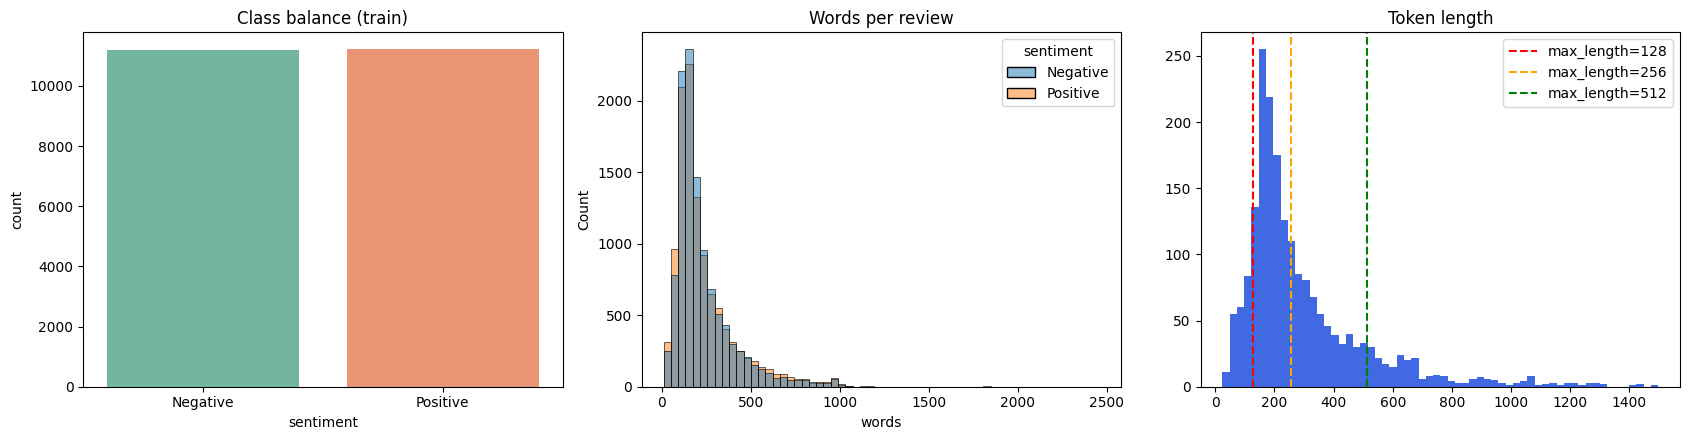

In [9]:
%matplotlib inline
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
sns.countplot(x="sentiment", data=df, palette="Set2", ax=ax[0]); ax[0].set_title("Class balance (train)")
sns.histplot(data=df, x="words", hue="sentiment", bins=60, ax=ax[1]); ax[1].set_title("Words per review")
ax[2].hist(lens, bins=60, color="royalblue")
for n, c in ((128, "red"), (256, "orange"), (512, "green")):
    ax[2].axvline(n, color=c, ls="--", label=f"max_length={n}")
ax[2].set_title("Token length"); ax[2].legend()
plt.tight_layout(); plt.savefig("reports/eda.png", dpi=150); plt.show()

## 4. Baseline: TF-IDF + Logistic Regression

In [10]:
import joblib
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from sklearn.pipeline import Pipeline

t0 = time.time()
vec = TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=200_000, sublinear_tf=True)
Xtr = vec.fit_transform(train_full["text"]); Xva = vec.transform(val_full["text"])
ytr, yva = train_full["label"], val_full["label"]

# trying a few values of C and picking the best one on validation
best = None
for C in (0.5, 1, 4, 16):
    clf = LogisticRegression(C=C, max_iter=2000, random_state=SEED).fit(Xtr, ytr)
    pred = clf.predict(Xva)
    acc, f1 = accuracy_score(yva, pred), f1_score(yva, pred)
    print(f"C={C:<5} val acc={acc:.4f}  f1={f1:.4f}")
    if best is None or acc > best[0]:
        best = (acc, f1, C, clf)

b_acc, b_f1, best_C, best_clf = best
joblib.dump(Pipeline([("tfidf", vec), ("clf", best_clf)]), "models/baseline.joblib")
log_experiment("tfidf+logreg", f"ngram=(1,2), C={best_C}", b_acc, b_f1, time.time() - t0)
print(f"best C={best_C}, val acc={b_acc:.4f}")

C=0.5   val acc=0.8932  f1=0.8944
C=1     val acc=0.9012  f1=0.9019
C=4     val acc=0.9085  f1=0.9089
C=16    val acc=0.9053  f1=0.9064
best C=4, val acc=0.9085


In [11]:
words_arr = np.array(vec.get_feature_names_out())
order = np.argsort(best_clf.coef_[0])
print("most negative:", ", ".join(words_arr[order[:15]]))
print("most positive:", ", ".join(words_arr[order[-15:]]))

most negative: bad, worst, awful, the worst, boring, poor, waste, terrible, nothing, worse, dull, poorly, no, unfortunately, horrible
most positive: enjoyable, superb, enjoyed, favorite, brilliant, loved, today, fun, the best, best, amazing, wonderful, perfect, excellent, great


## 5. DistilBERT fine-tuning

In [12]:
from torch.utils.data import DataLoader
from transformers import DataCollatorWithPadding, get_linear_schedule_with_warmup

def train_model(name, max_length, lr, batch_size, epochs, out_dir):
    print(f"\n== {name}: max_length={max_length}, lr={lr}, batch_size={batch_size}, epochs={epochs} ==")
    set_seed()
    tok = AutoTokenizer.from_pretrained(MODEL_NAME)

    def prep(ds):
        ds = ds.map(lambda b: tok(b["text"], truncation=True, max_length=max_length, return_token_type_ids=False),
                    batched=True, remove_columns=["text"])
        return ds.rename_column("label", "labels")

    collator = DataCollatorWithPadding(tok)
    train_loader = DataLoader(prep(train_full), batch_size=batch_size, shuffle=True, collate_fn=collator)
    val_loader = DataLoader(prep(val_full), batch_size=batch_size * 2, collate_fn=collator)

    model = load_clf(MODEL_NAME, num_labels=2, id2label=LABELS,
                     label2id={v: k for k, v in LABELS.items()}).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.01)
    total_steps = len(train_loader) * epochs
    scheduler = get_linear_schedule_with_warmup(optimizer, int(0.1 * total_steps), total_steps)
    scaler = torch.cuda.amp.GradScaler(enabled=use_amp)

    def evaluate_loader():
        model.eval()
        loss_sum, preds, labels = 0.0, [], []
        with torch.no_grad():
            for b in val_loader:
                b = {k: v.to(device) for k, v in b.items()}
                with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=use_amp):
                    out = model(**b)
                loss_sum += out.loss.item() * len(b["labels"])
                preds.extend(out.logits.argmax(-1).cpu().numpy()); labels.extend(b["labels"].cpu().numpy())
        return loss_sum / len(labels), accuracy_score(labels, preds), f1_score(labels, preds)

    history, best_acc, best_f1 = [], -1.0, 0.0
    t0 = time.time()
    for epoch in range(1, epochs + 1):
        model.train(); running = 0.0
        for b in tqdm(train_loader, desc=f"{name} epoch {epoch}/{epochs}"):
            b = {k: v.to(device) for k, v in b.items()}
            optimizer.zero_grad()
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=use_amp):
                loss = model(**b).loss
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer); scaler.update(); scheduler.step()
            running += loss.item()

        train_loss = running / len(train_loader)
        val_loss, val_acc, val_f1 = evaluate_loader()
        history.append({"epoch": epoch, "train_loss": train_loss, "val_loss": val_loss, "val_acc": val_acc, "val_f1": val_f1})
        print(f"epoch {epoch}: train_loss={train_loss:.4f} val_loss={val_loss:.4f} val_acc={val_acc:.4f} val_f1={val_f1:.4f}")

        # only keep the best epoch
        if val_acc > best_acc:
            best_acc, best_f1 = val_acc, val_f1
            os.makedirs(out_dir, exist_ok=True)
            model.save_pretrained(out_dir); tok.save_pretrained(out_dir)
            with open(os.path.join(out_dir, "train_config.json"), "w") as f:
                json.dump({"model_name": MODEL_NAME, "max_length": max_length, "lr": lr, "batch_size": batch_size,
                           "epochs": epochs, "best_epoch": epoch, "val_acc": val_acc, "val_f1": val_f1}, f, indent=2)

    seconds = time.time() - t0
    del model, optimizer, scheduler, scaler
    gc.collect(); torch.cuda.empty_cache()
    print(f"{name} done in {seconds/60:.1f} min, best val acc {best_acc:.4f}")
    return {"name": name, "out_dir": out_dir, "best_acc": best_acc, "best_f1": best_f1,
            "history": history, "seconds": seconds,
            "params": f"lr={lr}, bs={batch_size}, epochs={epochs}, max_len={max_length}, train_n={len(train_full)}"}

In [13]:
# 256 and 128 to compare lengths, 512 because a lot of reviews get cut off at 256
EXPERIMENTS = [
    {"name": "len256", "max_length": 256, "lr": 2e-5, "batch_size": 16, "epochs": 3, "out_dir": "models/distilbert_len256"},
    {"name": "len128", "max_length": 128, "lr": 3e-5, "batch_size": 16, "epochs": 2, "out_dir": "models/distilbert_len128"},
    {"name": "len512", "max_length": 512, "lr": 2e-5, "batch_size": 16, "epochs": 3, "out_dir": "models/distilbert_len512"},
]

results = []
for exp in EXPERIMENTS:
    r = train_model(**exp)
    log_experiment(MODEL_NAME, r["params"], r["best_acc"], r["best_f1"], r["seconds"])
    results.append(r)


== len256: max_length=256, lr=2e-05, batch_size=16, epochs=3 ==


Map:   0%|          | 0/22411 [00:00<?, ? examples/s]

Map:   0%|          | 0/2491 [00:00<?, ? examples/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

len512 epoch 3/3:   0%|          | 0/1401 [00:00<?, ?it/s]

epoch 3: train_loss=0.0935 val_loss=0.2511 val_acc=0.9370 val_f1=0.9364


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

len512 done in 17.3 min, best val acc 0.9370


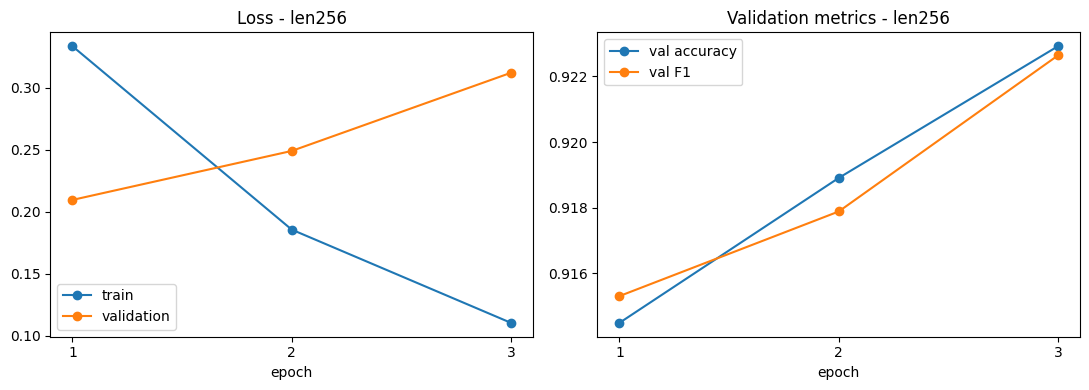

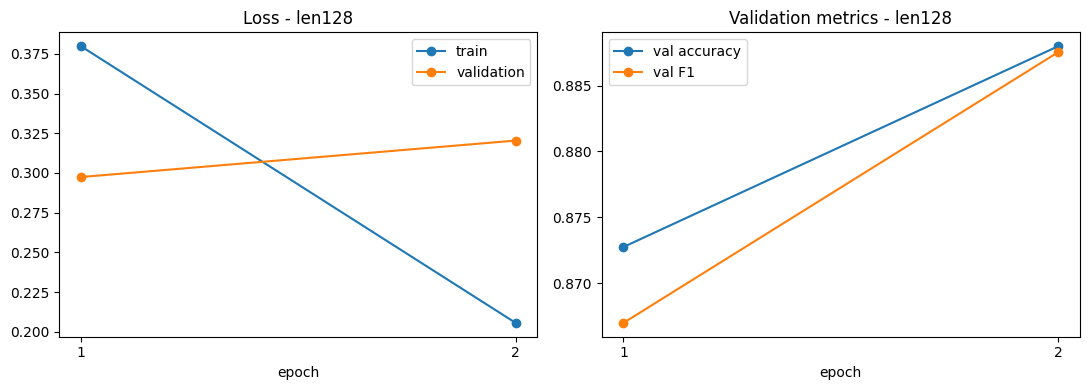

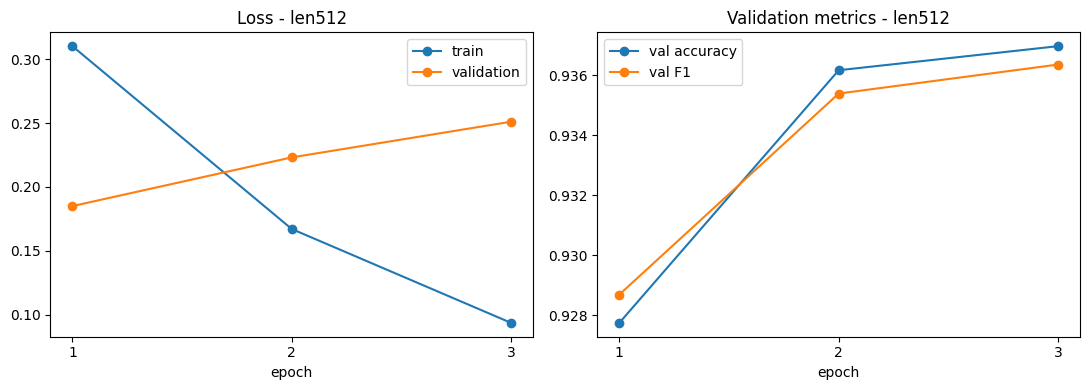

,model,params,val_accuracy,val_f1,train_time_s
0,tfidf+logreg,"ngram=(1,2), C=4",0.9085,0.9089,60.6
1,distilbert-base-uncased,"lr=2e-05, bs=16, epochs=3, max_len=256, train_...",0.9229,0.9226,571.2
2,distilbert-base-uncased,"lr=3e-05, bs=16, epochs=2, max_len=128, train_...",0.8880,0.8875,259.0
3,distilbert-base-uncased,"lr=2e-05, bs=16, epochs=3, max_len=512, train_...",0.9370,0.9364,1036.8


In [14]:
%matplotlib inline
for r in results:
    ep = [h["epoch"] for h in r["history"]]
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].plot(ep, [h["train_loss"] for h in r["history"]], marker="o", label="train")
    ax[0].plot(ep, [h["val_loss"] for h in r["history"]], marker="o", label="validation")
    ax[0].set_title(f"Loss - {r['name']}"); ax[0].set_xlabel("epoch"); ax[0].legend()
    ax[1].plot(ep, [h["val_acc"] for h in r["history"]], marker="o", label="val accuracy")
    ax[1].plot(ep, [h["val_f1"] for h in r["history"]], marker="o", label="val F1")
    ax[1].set_title(f"Validation metrics - {r['name']}"); ax[1].set_xlabel("epoch"); ax[1].legend()
    for x in ax: x.set_xticks(ep)
    plt.tight_layout(); plt.savefig(f"reports/training_curves_{r['name']}.png", dpi=150); plt.show()

display(pd.read_csv("reports/experiments.csv"))

In [15]:
# best run on validation becomes the final model
best_run = max(results, key=lambda r: r["best_acc"])
print(f"best run: {best_run['name']} (val acc {best_run['best_acc']:.4f})")
shutil.copytree(best_run["out_dir"], FINAL_DIR, dirs_exist_ok=True)
final_cfg = json.load(open(os.path.join(FINAL_DIR, "train_config.json")))
print(final_cfg)

best run: len512 (val acc 0.9370)
{'model_name': 'distilbert-base-uncased', 'max_length': 512, 'lr': 2e-05, 'batch_size': 16, 'epochs': 3, 'best_epoch': 3, 'val_acc': 0.9369731031714171, 'val_f1': 0.9363599513579246}


## 6. Evaluation on the test set

In [16]:
from sklearn.metrics import (classification_report, confusion_matrix, precision_recall_fscore_support,
                             roc_auc_score, roc_curve)

texts, y = list(test_ds["text"]), np.array(test_ds["label"])
print(len(texts), "test reviews")

baseline = joblib.load("models/baseline.joblib")
cfg = json.load(open(os.path.join(FINAL_DIR, "train_config.json")))
eval_tok = AutoTokenizer.from_pretrained(FINAL_DIR)
eval_model = load_clf(FINAL_DIR).to(device).eval()

def bert_probs(batch_texts, bs=32):
    # sorting by length so batches have less padding
    order = np.argsort([len(t) for t in batch_texts])
    probs = np.zeros(len(batch_texts))
    for i in range(0, len(batch_texts), bs):
        idx = order[i:i + bs]
        enc = eval_tok([batch_texts[j] for j in idx], truncation=True, max_length=cfg["max_length"],
                       padding=True, return_token_type_ids=False, return_tensors="pt").to(device)
        with torch.no_grad():
            logits = eval_model(**enc).logits
        probs[idx] = torch.softmax(logits.float(), -1)[:, 1].cpu().numpy()
    return probs

p_base = baseline.predict_proba(texts)[:, 1]
p_bert = bert_probs(texts)
probs = {"Baseline (TF-IDF + LogReg)": p_base, "DistilBERT": p_bert}

24676 test reviews


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

In [17]:
rows = []
for name, pr in probs.items():
    pred = (pr >= 0.5).astype(int)
    prec, rec, f1, _ = precision_recall_fscore_support(y, pred, average="binary")
    rows.append({"model": name, "accuracy": accuracy_score(y, pred), "precision": prec,
                 "recall": rec, "f1": f1, "roc_auc": roc_auc_score(y, pr)})
    print(f"\n=== {name} ===")
    print(classification_report(y, pred, target_names=list(LABELS.values()), digits=4))
results_tbl = pd.DataFrame(rows).round(4)
results_tbl


=== Baseline (TF-IDF + LogReg) ===
              precision    recall  f1-score   support

    Negative     0.9060    0.9010    0.9035     12265
    Positive     0.9027    0.9076    0.9051     12411

    accuracy                         0.9043     24676
   macro avg     0.9043    0.9043    0.9043     24676
weighted avg     0.9043    0.9043    0.9043     24676


=== DistilBERT ===
              precision    recall  f1-score   support

    Negative     0.9323    0.9305    0.9314     12265
    Positive     0.9315    0.9332    0.9323     12411

    accuracy                         0.9319     24676
   macro avg     0.9319    0.9319    0.9319     24676
weighted avg     0.9319    0.9319    0.9319     24676



,model,accuracy,precision,recall,f1,roc_auc
0,Baseline (TF-IDF + LogReg),0.9043,0.9027,0.9076,0.9051,0.9655
1,DistilBERT,0.9319,0.9315,0.9332,0.9323,0.9804


In [18]:
# is the difference between the two models just luck? exact mcnemar test
from scipy.stats import binomtest
base_ok = ((p_base >= 0.5).astype(int) == y)
bert_ok = ((p_bert >= 0.5).astype(int) == y)
only_bert = int((bert_ok & ~base_ok).sum())
only_base = int((base_ok & ~bert_ok).sum())
print("only DistilBERT right:", only_bert)
print("only baseline right:", only_base)
print("p-value:", binomtest(only_bert, only_bert + only_base, 0.5).pvalue)

only DistilBERT right: 1490
only baseline right: 810
p-value: 3.678900834206043e-46


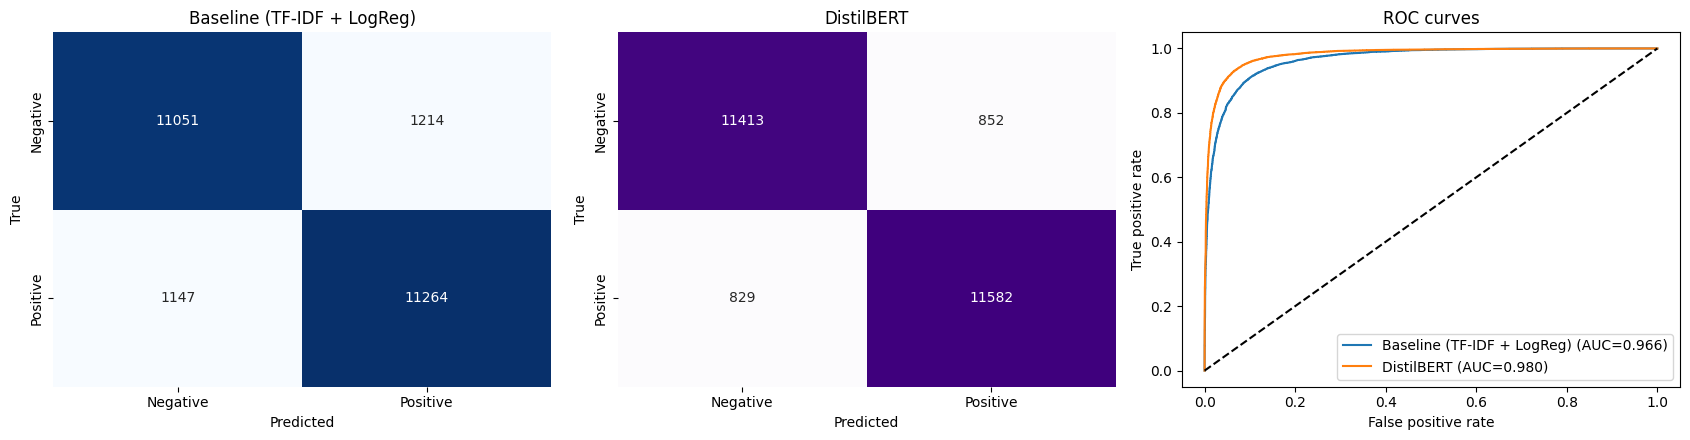

In [19]:
%matplotlib inline
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
for i, (name, pr) in enumerate(probs.items()):
    cm = confusion_matrix(y, (pr >= 0.5).astype(int))
    sns.heatmap(cm, annot=True, fmt="d", cmap=["Blues", "Purples"][i], cbar=False, ax=ax[i],
                xticklabels=LABELS.values(), yticklabels=LABELS.values())
    ax[i].set_title(name); ax[i].set_xlabel("Predicted"); ax[i].set_ylabel("True")
    fpr, tpr, _ = roc_curve(y, pr)
    ax[2].plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y, pr):.3f})")
ax[2].plot([0, 1], [0, 1], "k--"); ax[2].set_title("ROC curves")
ax[2].set_xlabel("False positive rate"); ax[2].set_ylabel("True positive rate"); ax[2].legend()
plt.tight_layout(); plt.savefig("reports/evaluation.png", dpi=150); plt.show()

In [20]:
def latency_ms(fn, sample, warmup=5):
    for t in sample[:warmup]: fn([t])
    times = []
    for t in sample:
        s = time.perf_counter(); fn([t]); times.append((time.perf_counter() - s) * 1000)
    return np.mean(times), np.percentile(times, 95)

# latency per single review, measured on the colab gpu
lat_rows = []
for name, fn in (("Baseline (TF-IDF + LogReg)", baseline.predict_proba), ("DistilBERT", bert_probs)):
    m, p95 = latency_ms(fn, texts[:100])
    lat_rows.append({"model": name, "latency_mean_ms": round(m, 2), "latency_p95_ms": round(p95, 2)})
latency_df = pd.DataFrame(lat_rows)
results_tbl.merge(latency_df, on="model").to_csv("reports/model_comparison.csv", index=False)
display(latency_df)

# accuracy for short / medium / long reviews
words = pd.Series(texts).str.split().str.len()
seg = pd.qcut(words, 3, labels=["short", "medium", "long"])
seg_tbl = pd.DataFrame({
    "baseline_acc":   [(((p_base >= .5).astype(int)) == y)[seg == s].mean() for s in seg.cat.categories],
    "distilbert_acc": [(((p_bert >= .5).astype(int)) == y)[seg == s].mean() for s in seg.cat.categories],
    "n_reviews":      [(seg == s).sum() for s in seg.cat.categories],
}, index=seg.cat.categories).round(4)
seg_tbl.to_csv("reports/accuracy_by_length.csv")
display(seg_tbl)

,model,latency_mean_ms,latency_p95_ms
0,Baseline (TF-IDF + LogReg),1.44,2.05
1,DistilBERT,11.18,18.91


,baseline_acc,distilbert_acc,n_reviews
short,0.9090,0.9377,8273
medium,0.9003,0.9330,8221
long,0.9037,0.9248,8182


In [21]:
# comparing all the trained lengths on the test set, long reviews especially
comp = []
for r in results:
    c = json.load(open(os.path.join(r["out_dir"], "train_config.json")))
    tk = AutoTokenizer.from_pretrained(r["out_dir"])
    m = load_clf(r["out_dir"]).to(device).eval()
    pr = np.zeros(len(texts))
    order = np.argsort([len(t) for t in texts])
    for i in range(0, len(texts), 32):
        idx = order[i:i + 32]
        enc = tk([texts[j] for j in idx], truncation=True, max_length=c["max_length"], padding=True,
                 return_token_type_ids=False, return_tensors="pt").to(device)
        with torch.no_grad():
            pr[idx] = torch.softmax(m(**enc).logits.float(), -1)[:, 1].cpu().numpy()
    ok = ((pr >= 0.5).astype(int) == y)
    comp.append({"experiment": r["name"], "max_length": c["max_length"], "test_acc": ok.mean(),
                 "short": ok[seg == "short"].mean(), "medium": ok[seg == "medium"].mean(), "long": ok[seg == "long"].mean()})
    del m; gc.collect(); torch.cuda.empty_cache()
comp_df = pd.DataFrame(comp).round(4)
comp_df.to_csv("reports/length_comparison.csv", index=False)
comp_df

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

,experiment,max_length,test_acc,short,medium,long
0,len256,256,0.9142,0.9374,0.9290,0.8759
1,len128,128,0.8818,0.9251,0.8919,0.8280
2,len512,512,0.9319,0.9377,0.9330,0.9248


In [22]:
pred = (p_bert >= 0.5).astype(int)
res_df = pd.DataFrame({"text": texts, "label": y, "pred": pred, "p_positive": p_bert,
                       "confidence": np.where(pred == 1, p_bert, 1 - p_bert), "words": words.values})
res_df["correct"] = res_df["label"] == res_df["pred"]
res_df.assign(text=res_df["text"].str.slice(0, 600)).to_csv("reports/bert_test_predictions.csv", index=False)

errors = res_df[~res_df["correct"]].sort_values("confidence", ascending=False)
errors.head(50).assign(text=lambda d: d["text"].str.slice(0, 600)).to_csv("reports/bert_errors.csv", index=False)

print(f"{len(errors)} mistakes out of {len(res_df)} reviews")
for _, r in errors.head(5).iterrows():
    print(f"TRUE: {LABELS[r.label]} | PRED: {LABELS[r.pred]} | conf {r.confidence:.0%}")
    print(r.text[:400], "...\n")

1681 mistakes out of 24676 reviews
TRUE: Negative | PRED: Positive | conf 100%
The Brave One is about a New York radio show host named Erica Bain (Jodie Foster). Her life is a dream living in the city she grew up in and loves. She has her great fiancé David (Naveen Andrews), whom she is planning to marry. But one night while Erica and David are out walking their dog, they are attacked and mugged by a group of degenerates, leaving David dead. Erica recovers but is heartbroken ...

TRUE: Negative | PRED: Positive | conf 100%
Lois Weber's film "Hypocrites" was and still kind of is a very bold and daring film. I enjoyed it and was very impressed by the filming and story of it. The priest sees the hypocrisy of the people in his church and tries to show them the "naked" truth. The people are appalled when he reveals the naked statue portraying truth, after failing to lead them to it and the few that did, help along the wa ...

TRUE: Negative | PRED: Positive | conf 100%
I went to see this 3 

## 7. Sample predictions and the app

In [23]:
def predict_sentiment(review_text):
    enc = eval_tok(review_text, truncation=True, max_length=cfg["max_length"],
                   return_token_type_ids=False, return_tensors="pt").to(device)
    with torch.no_grad():
        p = torch.softmax(eval_model(**enc).logits, dim=-1)[0]
    k = int(p.argmax())
    return LABELS[k], float(p[k])

samples = [
    "An absolute masterpiece with breathtaking cinematography and stellar acting!",
    "One of the worst, most boring movies I have ever endured. Complete waste of time.",
    "The visuals were gorgeous, but the plot dragged and the ending felt rushed.",
]
# sarcasm, true sentiment is negative
failure_case = ("Oh great, another two hours of my life I will never get back. "
                "What a thrilling experience, I was on the edge of my seat checking my watch.")

for s in samples:
    label, conf = predict_sentiment(s)
    print(f"{label:9s} ({conf:.1%})  {s}")
label, conf = predict_sentiment(failure_case)
print(f"\nfailure case (true: Negative) -> {label} ({conf:.1%})  {failure_case}")

Positive  (99.8%)  An absolute masterpiece with breathtaking cinematography and stellar acting!
Negative  (99.8%)  One of the worst, most boring movies I have ever endured. Complete waste of time.
Negative  (99.5%)  The visuals were gorgeous, but the plot dragged and the ending felt rushed.

failure case (true: Negative) -> Positive (99.4%)  Oh great, another two hours of my life I will never get back. What a thrilling experience, I was on the edge of my seat checking my watch.


In [24]:
# hand written test reviews, None = no right answer
tests = [
    ("Easy positive", "This film was fantastic. Brilliant acting, a gripping story, and I loved every minute of it.", 1),
    ("Easy positive", "A heartwarming, beautifully shot movie that I would happily watch again.", 1),
    ("Easy negative", "Terrible movie. The plot made no sense, the acting was wooden, and I walked out halfway through.", 0),
    ("Easy negative", "A complete waste of money. Dull, predictable and badly written.", 0),
    ("Negation", "I did not enjoy this movie at all.", 0),
    ("Negation", "This is not a bad film; in fact, it is surprisingly good.", 1),
    ("Mixed opinions", "The acting was superb, but the story was so slow and confusing that I nearly fell asleep.", 0),
    ("Mixed opinions", "Great visuals and music, although the ending was a bit rushed. Overall I enjoyed it.", 1),
    ("Sarcasm", "Oh great, another two hours of my life I will never get back. What a thrilling experience.", 0),
    ("Sarcasm", "Wow, what a masterpiece. I only checked my watch forty times.", 0),
    ("Very short", "Loved it!", 1),
    ("Very short", "Awful.", 0),
    ("Other domain", "The delivery was late and the package arrived damaged. Customer support never replied.", 0),
    ("Other domain", "Fast shipping, great quality, and the support team solved my issue within minutes.", 1),
    ("Other domain", "The hotel room was spotless and the staff were incredibly friendly.", 1),
    ("Other domain", "The app keeps crashing every time I open it. Very frustrating.", 0),
    ("Long review (truncation)",
     "The first half of this film is wonderful, with gorgeous scenes and great performances. " * 40
     + "However, the ending ruined everything and I regret watching it. A terrible conclusion and a disappointing movie overall.", 0),
    ("Neutral (no right answer)", "The movie is about a detective who investigates a murder in a small town.", None),
]

rows = []
for group, text, expected in tests:
    label, conf = predict_sentiment(text)
    base_label = LABELS[int(baseline.predict_proba([text])[0, 1] >= 0.5)]
    rows.append({"group": group, "text": text[:60] + ("..." if len(text) > 60 else ""),
                 "expected": "-" if expected is None else LABELS[expected],
                 "distilbert": label, "confidence": f"{conf:.0%}",
                 "distilbert_result": "n/a" if expected is None else ("PASS" if label == LABELS[expected] else "FAIL"),
                 "baseline": base_label,
                 "baseline_result": "n/a" if expected is None else ("PASS" if base_label == LABELS[expected] else "FAIL")})
test_df = pd.DataFrame(rows)
test_df.to_csv("reports/manual_tests.csv", index=False)
display(test_df)

scored = test_df[test_df["distilbert_result"] != "n/a"]
print("DistilBERT:", (scored["distilbert_result"] == "PASS").sum(), "of", len(scored), "passed")
print("Baseline:  ", (scored["baseline_result"] == "PASS").sum(), "of", len(scored), "passed")
print(scored.groupby("group")[["distilbert_result", "baseline_result"]].agg(lambda s: f"{(s == 'PASS').sum()}/{len(s)}"))

,group,text,expected,distilbert,confidence,distilbert_result,baseline,baseline_result
0,Easy positive,"This film was fantastic. Brilliant acting, a g...",Positive,Positive,100%,PASS,Positive,PASS
1,Easy positive,"A heartwarming, beautifully shot movie that I ...",Positive,Positive,100%,PASS,Positive,PASS
2,Easy negative,"Terrible movie. The plot made no sense, the ac...",Negative,Negative,100%,PASS,Negative,PASS
3,Easy negative,"A complete waste of money. Dull, predictable a...",Negative,Negative,100%,PASS,Negative,PASS
4,Negation,I did not enjoy this movie at all.,Negative,Negative,99%,PASS,Negative,PASS
5,Negation,"This is not a bad film; in fact, it is surpris...",Positive,Positive,100%,PASS,Positive,PASS
6,Mixed opinions,"The acting was superb, but the story was so sl...",Negative,Negative,99%,PASS,Negative,PASS
7,Mixed opinions,"Great visuals and music, although the ending w...",Positive,Positive,100%,PASS,Positive,PASS
8,Sarcasm,"Oh great, another two hours of my life I will ...",Negative,Positive,100%,FAIL,Positive,FAIL
9,Sarcasm,"Wow, what a masterpiece. I only checked my wat...",Negative,Positive,99%,FAIL,Positive,FAIL


DistilBERT: 14 of 17 passed
Baseline:   11 of 17 passed
                         distilbert_result baseline_result
group                                                     
Easy negative                          2/2             2/2
Easy positive                          2/2             2/2
Long review (truncation)               0/1             0/1
Mixed opinions                         2/2             2/2
Negation                               2/2             2/2
Other domain                           4/4             1/4
Sarcasm                                0/2             0/2
Very short                             2/2             2/2


In [25]:
%%writefile app.py
import json
import os

import numpy as np
import pandas as pd
import streamlit as st
import torch
from transformers import AutoModelForSequenceClassification, AutoTokenizer

MODEL_DIR = os.environ.get("MODEL_DIR", "models/distilbert_sentiment")
LABELS = {0: "Negative", 1: "Positive"}
LOW_CONF = 0.75

SAMPLES = {
    "Positive example": "An absolute masterpiece with breathtaking cinematography and stellar acting!",
    "Negative example": "One of the worst, most boring movies I have ever endured. Complete waste of time.",
    "Mixed example": "The visuals were gorgeous, but the plot dragged and the ending felt rushed.",
    "Known failure case (sarcasm)": "Oh great, another two hours of my life I will never get back. "
                                    "What a thrilling experience, I was on the edge of my seat checking my watch.",
}
FAILURE_NOTE = ("Failure case: this review is negative but the model predicts Positive with very high confidence. "
                "It picks up on words like 'great' and 'thrilling' and misses the sarcasm.")

st.set_page_config(page_title="Review Sentiment Analyzer", layout="wide")


@st.cache_resource
def load_model(path):
    tok = AutoTokenizer.from_pretrained(path)
    model = AutoModelForSequenceClassification.from_pretrained(path).eval()
    dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    cfg_path = os.path.join(path, "train_config.json")
    max_len = json.load(open(cfg_path)).get("max_length", 256) if os.path.exists(cfg_path) else 256
    return tok, model.to(dev), max_len, dev


def predict(texts, bs=16):
    tok, model, max_len, dev = load_model(MODEL_DIR)
    out = []
    for i in range(0, len(texts), bs):
        enc = tok(texts[i:i + bs], truncation=True, max_length=max_len, padding=True,
                  return_token_type_ids=False, return_tensors="pt").to(dev)
        with torch.no_grad():
            probs = torch.softmax(model(**enc).logits, -1).cpu().numpy()
        out.extend(probs)
    out = np.array(out)
    pred = out.argmax(1)
    return [LABELS[p] for p in pred], out.max(1), out[:, 1]


st.title("Customer Review Sentiment Analyzer")
st.caption("Fine-tuned DistilBERT trained on IMDb reviews. Predictions should support human review, "
           "not be the only basis for customer service decisions.")

if not os.path.isdir(MODEL_DIR):
    st.error(f"Model folder '{MODEL_DIR}' not found.")
    st.stop()

tab1, tab2, tab3 = st.tabs(["Single review", "Batch (CSV)", "Dashboard"])

with tab1:
    choice = st.selectbox("Example reviews", ["(type my own)"] + list(SAMPLES))
    text = st.text_area("Review text", value=SAMPLES.get(choice, ""), height=150, key=f"txt_{choice}")
    if choice.startswith("Known failure"):
        st.info(FAILURE_NOTE)
    if st.button("Analyze", type="primary") and text.strip():
        (label,), (conf,), (p_pos,) = predict([text])
        c1, c2 = st.columns(2)
        c1.metric("Predicted sentiment", label)
        c2.metric("Confidence", f"{conf:.1%}")
        st.progress(float(p_pos), text=f"P(positive) = {p_pos:.1%}")
        if conf < LOW_CONF:
            st.warning("Low confidence, this one should be checked by a person.")
        tok, _, max_len, _ = load_model(MODEL_DIR)
        if len(tok(text)["input_ids"]) > max_len:
            st.warning(f"Review is longer than {max_len} tokens, the end was cut off.")

with tab2:
    up = st.file_uploader("CSV file with a column of reviews", type="csv")
    if up:
        data = pd.read_csv(up)
        col = st.selectbox("Text column", data.columns)
        if st.button("Classify all reviews"):
            with st.spinner("Classifying..."):
                labels, conf, _ = predict(data[col].astype(str).tolist())
            data["sentiment"], data["confidence"] = labels, np.round(conf, 4)
            st.bar_chart(data["sentiment"].value_counts())
            st.subheader("Negative reviews, most confident first")
            st.dataframe(data[data["sentiment"] == "Negative"].sort_values("confidence", ascending=False))
            st.download_button("Download results", data.to_csv(index=False), "predictions.csv")

with tab3:
    pred_path = "reports/bert_test_predictions.csv"
    if not os.path.exists(pred_path):
        st.info("reports/bert_test_predictions.csv is missing.")
    else:
        df = pd.read_csv(pred_path)
        df["true"], df["predicted"] = df["label"].map(LABELS), df["pred"].map(LABELS)

        if os.path.exists("reports/model_comparison.csv"):
            st.subheader("Model comparison (same test set)")
            st.dataframe(pd.read_csv("reports/model_comparison.csv"), hide_index=True)

        c1, c2 = st.columns(2)
        with c1:
            st.subheader("Sentiment distribution")
            st.bar_chart(pd.DataFrame({"true": df["true"].value_counts(),
                                       "predicted": df["predicted"].value_counts()}))
        with c2:
            st.subheader("Model confidence")
            hist, edges = np.histogram(df["confidence"], bins=10, range=(0.5, 1.0))
            st.bar_chart(pd.DataFrame({"reviews": hist}, index=[f"{e:.2f}" for e in edges[:-1]]))

        st.subheader("Accuracy by confidence band")
        band = pd.cut(df["confidence"], [0.5, 0.6, 0.7, 0.8, 0.9, 1.0], include_lowest=True)
        st.dataframe(df.groupby(band, observed=True)["correct"].agg(["mean", "count"]).round(3))

        if os.path.exists("reports/accuracy_by_length.csv"):
            st.subheader("Accuracy by review length")
            st.dataframe(pd.read_csv("reports/accuracy_by_length.csv", index_col=0))

        st.subheader("Sample errors (most confident first)")
        st.dataframe(df[~df["correct"]].sort_values("confidence", ascending=False)
                     [["true", "predicted", "confidence", "text"]].head(30), hide_index=True)

Writing app.py


In [26]:
%%writefile requirements.txt
torch
transformers>=4.40
datasets
accelerate
evaluate
scikit-learn
pandas
numpy
matplotlib
seaborn
joblib
streamlit
tqdm
scipy

Writing requirements.txt


In [27]:
%%writefile README.md
# Customer Review Sentiment Analysis using BERT

Classifies reviews as positive or negative (0 = negative, 1 = positive).
Data: IMDb Large Movie Review Dataset, https://huggingface.co/datasets/stanfordnlp/imdb
Models: TF-IDF + Logistic Regression (baseline) and fine-tuned DistilBERT.

## Files
- `Capstone_Sentiment_Analysis_Colab.ipynb` - data, EDA, baseline, DistilBERT experiments, evaluation
- `app.py` - Streamlit app (single review, CSV batch, dashboard)
- `models/` - saved baseline and the final DistilBERT model
- `reports/` - plots, metric tables, experiment log, error analysis
- `requirements.txt`, `Dockerfile`

## Setup
```
pip install -r requirements.txt
```

## Run the app
```
streamlit run app.py
```
Then open http://localhost:8501. The app loads the saved model from `models/distilbert_sentiment`, nothing is retrained.

## Reproduce
Open the notebook in Google Colab with a T4 GPU and run all cells (about an hour).

## Limitations
- Trained on movie reviews only, product or service reviews may behave differently.
- Reviews longer than the token limit are cut off.
- Sarcasm is a common failure, the model can be confidently wrong.
- Predictions should support human review, not replace it.

Writing README.md


In [28]:
%%writefile Dockerfile
FROM python:3.11-slim
WORKDIR /app
COPY requirements.txt .
RUN pip install --no-cache-dir -r requirements.txt
COPY app.py README.md ./
COPY models ./models
COPY reports ./reports
EXPOSE 8501
CMD ["streamlit", "run", "app.py", "--server.port=8501", "--server.address=0.0.0.0"]

Writing Dockerfile


## 8. Export

In [29]:
from google.colab import files

# only the final model goes in the zip, not every experiment
shutil.rmtree("package", ignore_errors=True)
os.makedirs("package/models")
for f in ["app.py", "README.md", "requirements.txt", "Dockerfile"]:
    shutil.copy(f, "package")
shutil.copy("models/baseline.joblib", "package/models")
shutil.copytree(FINAL_DIR, "package/models/distilbert_sentiment")
shutil.copytree("reports", "package/reports")

zip_path = shutil.make_archive("capstone_results", "zip", "package")
print(zip_path, f"{os.path.getsize(zip_path)/1e6:.0f} MB")
files.download(zip_path)

/content/capstone_results.zip 258 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [30]:
# optional: run the app inside colab through a tunnel (this cell keeps running, stop it when done)
!pip -q install streamlit
!wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O cloudflared
!chmod +x cloudflared
!nohup streamlit run app.py --server.port 8501 --server.headless true > /content/streamlit_logs.txt 2>&1 &
!sleep 8
!./cloudflared tunnel --no-autoupdate --url http://localhost:8501

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.3/10.3 MB 38.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 116.1 MB/s eta 0:00:00
2026-10-10T16:40:07Z INF Thank you for trying Cloudflare Tunnel. Doing so, without a Cloudflare account, is a quick way to experiment and try it out. However, be aware that these account-less Tunnels have no uptime guarantee, are subject to the Cloudflare Online Services Terms of Use (https://www.cloudflare.com/website-terms/), and Cloudflare reserves the right to investigate your use of Tunnels for violations of such terms. If you intend to use Tunnels in production you should use a pre-created named tunnel by following: https://developers.cloudflare.com/cloudflare-one/connections/connect-apps
2026-10-10T16:40:07Z INF Requesting new quick Tunnel on trycloudflare.com...
2026-10-10T16:40:15Z INF +--------------------------------------------------------------------------------------------+
2026-10-10T16:40:15Z INF |  Your quick Tun